In [9]:
# Importing all of the relevant programs we will need for this project. 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import csv 
import numpy as np
import plotly.express as px

# Reading in the data set and displaing the first 5 rows of the data set. 
# Fixed a UnicodeError: we used the csv module from Python to process the code line by line 
# without worrying about whether a row has 13, 14, or 17 fields 
# due to certain inconsistencies in the number of columns in some of the rows. 

df = pd.DataFrame(
    list(csv.reader(open("kickstarter.csv", encoding="cp1252")))
)

## Overview of the data frame, including the numeber of rows and columns, data types, and memory usage. 

display(df.head())
print("Dataset shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)

# Dropping columns with missing values
df = df.dropna(axis=1)

#Looking at 13, 14, 15, 16 differences from the rest

print("Testing") 

FileNotFoundError: [Errno 2] No such file or directory: 'kickstarter.csv'

In [370]:

# Fixing the category issue here where it was originally an integer, and it is now its actual label. 
df_clean = df.copy() 
df.head() #Will stop here, and take a look at the summary statistics at a later time today! 

#you can only consider rows that have above a certain threshold. 
#or bin the small categories called others. 
#df["category"].value_counts() #this will give you the counts of each category.



,0,1,2,3,4,5,6,7,8,9,10,11,12
0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283


In [371]:
# Information about the data frame, including the number of rows and columns, data types, and memory usage.
df.columns 
df.columns = df.iloc[0]  # Set the first row as column names
df = df.iloc[1:]  # Remove the first row

In [372]:
df.head()
df.columns 

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Check the cleaned column names
print(df.columns.tolist())

['ID', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd pledged']


In [10]:
print(df.head())
print(df.columns)


NameError: name 'df' is not defined

In [350]:
top_10_categories = df['category'].value_counts().head(10).index
top_10_categories 

filtered_df = df[df['category'].isin(top_10_categories)]
filtered_df 

#What percentage do the categories take up in the data set. 

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
6,1000023410,Support Solar Roasted Coffee & Green Energy! ...,Food,Food,USD,2014-12-21 18:30:44,1000,2014-12-01 18:30:44,1205,successful,16,US,1205
8,1000034518,SPIN - Premium Retractable In-Ear Headphones w...,Product Design,Design,USD,2014-05-29 18:14:43,125000,2014-04-24 18:14:43,8233,canceled,58,US,8233
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323736,999934908,The Manual Bar Blade,Product Design,Design,USD,2015-12-15 06:59:00,3500,2015-11-23 07:33:14,6169,successful,120,US,6169
323740,999955533,Cards and Chit Network Season 2! (Canceled),Tabletop Games,Games,USD,2016-02-23 16:03:27,500,2016-01-24 16:03:27,121,canceled,5,US,121
323743,999971898,Beach Wrestling Documentary,Documentary,Film & Video,NOK,2015-04-28 21:30:33,20000,2015-03-29 21:30:33,21500,successful,36,NO,2698.974335
323744,999972264,Islanda,Documentary,Film & Video,USD,2012-03-16 03:31:10,1700,2012-02-15 04:31:10,25,failed,1,US,25


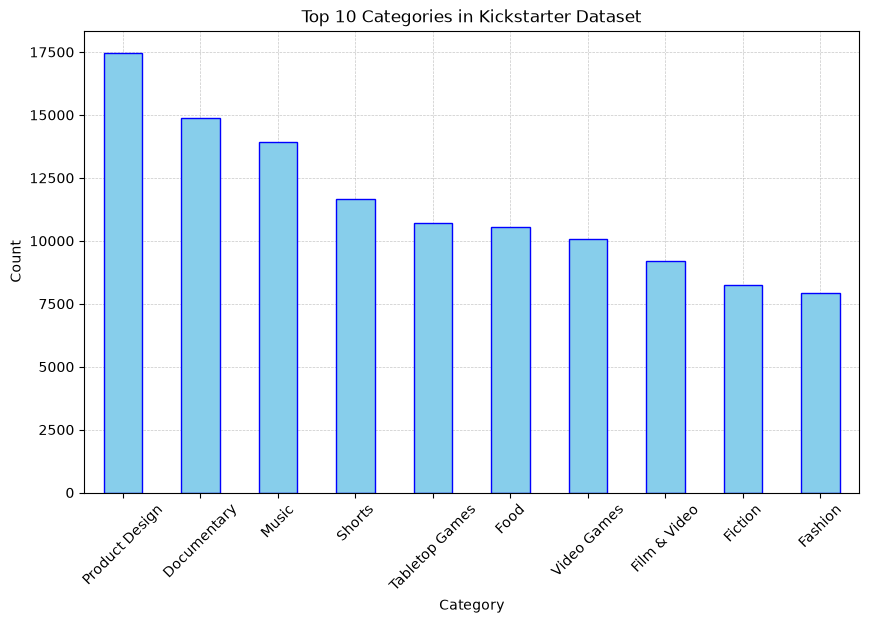

In [351]:
# Filtering the DataFrame to include only the top 10 categories based on their counts.
filtered_df = df[df['category'].isin(top_10_categories)] 
filtered_df

#Needs to show the 10 categories and their counts.

ax = filtered_df['category'].value_counts().plot(kind='bar', figsize=(10, 6), color='skyblue', edgecolor='blue')
plt.title('Top 10 Categories in Kickstarter Dataset')
plt.xlabel('Category')
plt.ylabel('Count') 


ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)


In [352]:
#Filtering to the Top 5 Most Popular Main Categories in the Kickstarter Dataset.

top_5_main_categories = df['main_category'].value_counts().head(5).index
top_5_main_categories 

filtered_df = df[df['main_category'].isin(top_5_main_categories)]
filtered_df 

#Future Question: What percentage do the main categories categories take up in the data set?

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323745,999976312,Angela's Poetry (Canceled),Poetry,Publishing,CAD,2014-09-20 03:46:07,5500,2014-08-06 03:46:07,0,canceled,0,CA,0
323746,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17 02:35:30,50000,2014-09-17 02:35:30,25,canceled,1,US,25
323747,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19 03:35:14,1500,2011-06-22 03:35:14,155,failed,5,US,155
323748,999986353,Walls of Remedy- New lesbian Romantic Comedy f...,Narrative Film,Film & Video,USD,2010-08-16 05:59:00,15000,2010-07-01 19:40:30,20,failed,1,US,20


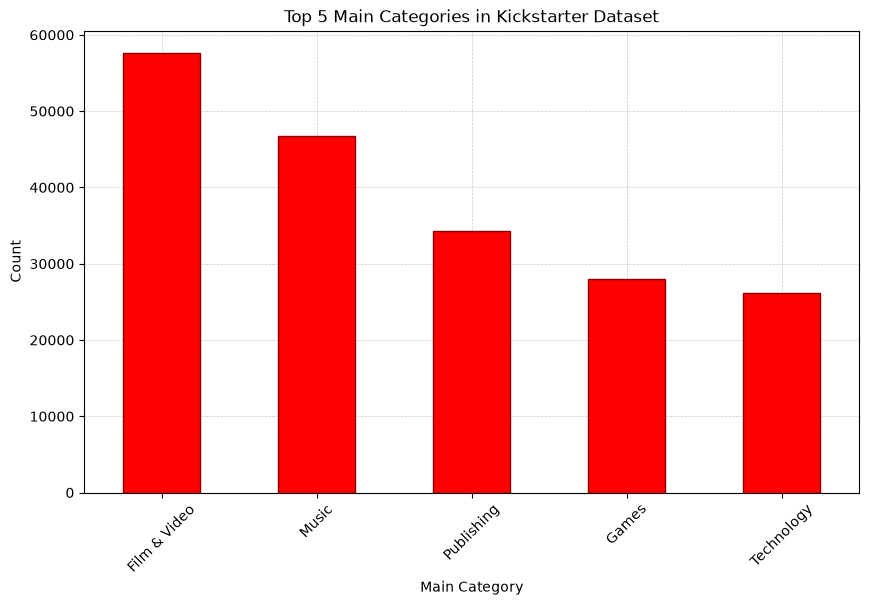

In [353]:
# Filtering the DataFrame to include only the top 5 categories based on their counts.
filtered_df = df[df['main_category'].isin(top_5_main_categories)]  
filtered_df

#Needs to show the 5 categories and their counts.

ax= filtered_df['main_category'].value_counts().plot(kind='bar', figsize=(10, 6), color='red', edgecolor='darkred')
plt.title('Top 5 Main Categories in Kickstarter Dataset')
plt.xlabel('Main Category')
plt.ylabel('Count') 

ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)

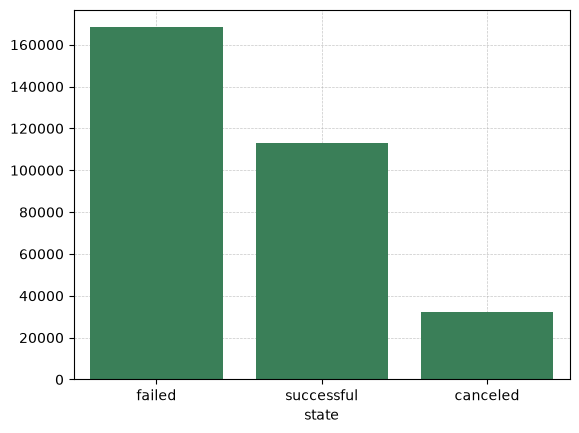

In [354]:
ax= sns.barplot(x=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state']
    .value_counts().index, color='seagreen', y=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state'].value_counts().values)
ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

In [1]:
#Need to create a data set for film and video, music, and publishing, and compare the backer trends for each of these categories.

print(df['state'].isin(['successful','failed','canceled']).describe())

NameError: name 'df' is not defined

In [356]:
print(df[['goal', 'pledged', 'backers', 'usd pledged']].describe())

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))


0         goal pledged backers usd pledged
count   323750  323750  323750      323750
unique    8188   55598    3592       94377
top       5000       0       0           0
freq     25520   45784   48863       50462

Missing values:
0
ID               0
name             0
category         0
main_category    0
currency         0
deadline         0
goal             0
launched         0
pledged          0
state            0
backers          0
country          0
usd pledged      0
dtype: int64


In [357]:
# Keep only completed projects with clear successful/failed outcomes
completed = df[df['state'].isin(['successful', 'failed', 'canceled'])].copy()

# Calculate the success rate for each main category
success_rates = (completed.assign(success=completed['state'].eq('successful'))
    .groupby('main_category')['success']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(success_rates.round(2))

main_category
Dance           63.15
Theater         60.66
Comics          52.27
Music           49.58
Art             40.85
Film & Video    38.07
Design          34.43
Games           34.30
Publishing      30.83
Photography     30.46
Food            25.28
Fashion         24.03
Crafts          23.93
Journalism      21.94
Technology      20.12
Name: success, dtype: float64


In [358]:
df['launched'] = pd.to_datetime(df['launched'], errors='coerce')
df['deadline'] = pd.to_datetime(df['deadline'], errors='coerce')

df['campaign_days'] = (df['deadline'] - df['launched']).dt.days

print(df['campaign_days'].describe())

count    323118.000000
mean         34.535851
std          71.180066
min           1.000000
25%          30.000000
50%          30.000000
75%          37.000000
max       16739.000000
Name: campaign_days, dtype: float64


In [359]:
print(df['category'].describe())

count             323750
unique               771
top       Product Design
freq               17477
Name: category, dtype: object


In [360]:
print(df['main_category'].describe())

count           323750
unique             120
top       Film & Video
freq             57679
Name: main_category, dtype: object


In [361]:
print(df['currency'].describe())

count     323750
unique        37
top          USD
freq      260298
Name: currency, dtype: object


In [362]:
print(df['deadline'].describe())

count                        323118
mean     2014-05-18 07:38:15.080150
min             2009-05-03 08:59:59
25%      2013-02-18 21:25:36.750000
50%             2014-09-07 17:59:12
75%      2015-09-09 16:37:25.500000
max             2017-02-04 08:54:55
Name: deadline, dtype: object


In [344]:
print(df['goal'].describe())

count     323750
unique      8188
top         5000
freq       25520
Name: goal, dtype: object


In [363]:
print(df['launched'].describe())

count                        323126
mean     2014-04-13 14:30:42.331155
min             1970-01-01 01:00:00
25%      2013-01-17 06:50:43.750000
50%      2014-08-05 01:18:33.500000
75%             2015-08-06 21:06:54
max             2016-12-06 10:18:31
Name: launched, dtype: object


In [364]:
print(df['pledged'].describe())

count     323750
unique     55598
top            0
freq       45784
Name: pledged, dtype: object


In [365]:
print(df['state'].describe())

count     323750
unique       410
top       failed
freq      168221
Name: state, dtype: object


In [366]:
print(df['backers'].describe())

count     323750
unique      3592
top            0
freq       48863
Name: backers, dtype: object


In [367]:
print(df['country'].describe())



count     323750
unique       162
top           US
freq      257565
Name: country, dtype: object


In [368]:
print(df['usd pledged'].describe())


count     323750
unique     94377
top            0
freq       50462
Name: usd pledged, dtype: object


In [ ]:
x= 323750

y= 168221 

z = 113081

a = 32354


